# Análise dos resultados — Renvest (TCC 2)

Consolida as quatro frentes da avaliação (Seção 4.7 e 4.8 do TCC; Seções 6.9–6.11 do `PLANO_CORRECOES_TCC.md`):

| Frente | Fonte de dados | Seção |
|---|---|---|
| A — RAGAS | `data/eval/ragas_v2.csv` | 1 |
| D — Operacional | `data/eval/eval_set_v2.json` (+ `cold_start.csv`, se existir) | 2 |
| B — Especialistas | `data/eval/especialistas_codificacao.xlsx` + planilhas devolvidas em `data/respostas_especialistas/` | 3 |
| C — Iniciantes | Forms exportado em `data/respostas_especialistas/` | 4 e 5 |
| Triangulação e critérios | tudo acima | 6 e 7 |

Todas as tabelas saem em `data/eval/analise/tabelas/` (`.csv` e `.tex` no estilo do TCC, com vírgula decimal) e as figuras em `data/eval/analise/figuras/` (`.pdf` para o LaTeX e `.png`).
Nenhum dado de entrada é alterado.

**Rodar:** com o `venv-eval` (já tem pandas). Instale o que faltar: `pip install scipy matplotlib openpyxl jupyter`.

In [1]:
# ---------------------------------------------------------------- configuração
import json, re, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
pd.set_option("display.max_colwidth", 80, "display.width", 200)

# raiz do rag-finance-agent: sobe a partir da pasta atual até achar data/eval
ROOT = Path.cwd()
while not (ROOT / "data" / "eval").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
EVAL = ROOT / "data" / "eval"
RESP = ROOT / "data" / "respostas_especialistas"
OUT = EVAL / "analise"; TAB = OUT / "tabelas"; FIG = OUT / "figuras"
for p in (TAB, FIG):
    p.mkdir(parents=True, exist_ok=True)
print("ROOT:", ROOT)

# ---------------------------------------------------------------- parâmetros (fixados antes de olhar os resultados)
LIMIAR = {
    "faithfulness": 0.80,          # critério 1
    "corretas_especialistas": 0.80,# critério 2
    "n4_minimo": 2,                # critério 5
    "tarefas": {"T1": .80, "T2": .80, "T3": .70, "T4": .80},  # critério 6
    "bus": 4.0,                    # critério 7
    "tam": 5.0,                    # critério 8
    "latencia_s": 8.0,             # critério 9
    "compreensao": 4.0,            # critério 10
}
# Casos de falha (Seção 4.8.3): "baixo" em cada frente
FALHA = {"fc_rag": 0.40, "recall": 0.50, "faith": 0.70, "esp_score": 0.50, "latencia_s": 8.0}  # esp_score: escore < 0,5 = ao menos um "incorreta"

# Preços da OpenAI (USD por 1M tokens). Conferir em https://openai.com/api/pricing e anotar a data no texto.
PRECO = {"data_tabela": "17/11/2026",
         "gpt-4o-mini_in": 0.15, "gpt-4o-mini_out": 0.60, "embedding_small": 0.02}
INTERACOES_USUARIO_MES = 100      # projeção de uso mensal (perguntas por usuário/mês) — ajuste e justifique no texto
USD_BRL = None                    # ex.: 5.40 para mostrar também em reais

# Cores (paleta categórica validada: slot 1 azul, slot 2 laranja; divergente azul <-> vermelho com meio cinza)
COR = {"RAG": "#2a78d6", "B1": "#eb6834", "neutro": "#d9d8d4", "texto": "#52514e"}
DIV5 = ["#e34948", "#f1a3a2", "#d9d8d4", "#86b6ef", "#2a78d6"]
DIV7 = ["#b83232", "#e34948", "#f1a3a2", "#d9d8d4", "#86b6ef", "#3987e5", "#1c5cab"]
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#b5b4ae", "axes.labelcolor": COR["texto"],
                     "xtick.color": COR["texto"], "ytick.color": COR["texto"],
                     "axes.grid": True, "grid.color": "#ecebe8", "grid.linewidth": .8,
                     "axes.axisbelow": True, "figure.dpi": 110, "savefig.bbox": "tight"})
NIVEIS = ["N1", "N2", "N3", "N4"]

ROOT: /home/claude/rag-finance-agent


In [2]:
# ---------------------------------------------------------------- utilitários de saída
def br(x, casas=2):
    # número com vírgula decimal (ABNT); deixa texto como está
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "--"
    if isinstance(x, (int, np.integer)):
        return f"{x}"
    if isinstance(x, (float, np.floating)):
        return f"{x:.{casas}f}".replace(".", ",")
    return str(x)

def pct(x, casas=0):
    return "--" if x is None or (isinstance(x, float) and math.isnan(x)) else f"{100*x:.{casas}f}%".replace(".", ",")

def tex_esc(s):
    s = str(s)
    for a, b in [("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"), ("_", r"\_"), ("#", r"\#"), ("$", r"\$")]:
        s = s.replace(a, b)
    for a, b in [("≥", r"$\geq$"), ("≤", r"$\leq$"), ("κ", r"$\kappa$"), ("α", r"$\alpha$"), ("ρ", r"$\rho$")]:
        s = s.replace(a, b)
    return s

def cols(*specs):
    # especificação de colunas com largura fixa: ("l", 2.0) -> alinhada à esquerda com 2 cm; ("c", 1.5) -> centralizada
    al = {"l": r"\raggedright", "c": r"\centering", "r": r"\raggedleft"}
    return "|" + "|".join(rf">{{{al[a]}\arraybackslash}}p{{{w}cm}}" for a, w in specs) + "|"

def salvar_tabela(df, nome, titulo, label, fonte="Elaborado pelo autor.", casas=2, colfmt=None, quadro=False, escapar=True, tam="small"):
    # grava .csv (dados crus) e .tex no estilo do TCC (bordas, arraystretch 1.25, fonte abaixo)
    df.to_csv(TAB / f"{nome}.csv", index=False, encoding="utf-8-sig")
    amb = "quadro" if quadro else "table"
    colfmt = colfmt or "|" + "|".join(["l"] + ["c"] * (df.shape[1] - 1)) + "|"
    fmt = lambda v: (tex_esc(v) if escapar else v) if isinstance(v, str) else br(v, casas)
    linhas = [" & ".join(r"\textbf{" + tex_esc(c) + "}" for c in df.columns) + r" \\ \hline"]
    for _, r in df.iterrows():
        linhas.append(" & ".join(fmt(v) for v in r.values) + r" \\ \hline")
    tex = "\n".join([
        rf"\begin{{{amb}}}[H]", r"    \centering", rf"    \caption{{{titulo}}}", rf"    \label{{{label}}}",
        r"    \renewcommand{\arraystretch}{1.25}", rf"    \{tam}",
        rf"    \begin{{tabular}}{{{colfmt}}}", r"        \hline",
        *["        " + l for l in linhas],
        r"    \end{tabular}", r"    \par\smallskip", rf"    \raggedright\small Fonte: {fonte}",
        r"    \renewcommand{\arraystretch}{1}", rf"\end{{{amb}}}", ""])
    (TAB / f"{nome}.tex").write_text(tex, encoding="utf-8")
    return df

def salvar_fig(fig, nome):
    for ext in ("pdf", "png"):
        fig.savefig(FIG / f"{nome}.{ext}", dpi=200)
    plt.show()

## 0. Carga dos dados e registro do congelamento

In [3]:
es = json.loads((EVAL / "eval_set_v2.json").read_text(encoding="utf-8"))
META = es["metadados"]
itens = pd.DataFrame(es["itens"])
print(json.dumps(META, ensure_ascii=False, indent=1))
assert len(itens) == 16, "o conjunto congelado deveria ter 16 perguntas"

ragas_meta = json.loads((EVAL / "ragas_v2_meta.json").read_text(encoding="utf-8"))
assert ragas_meta["conjunto"]["git"]["commit"] == META["git"]["commit"], "RAGAS rodou sobre outro conjunto!"
print("\nRAGAS:", ragas_meta["ragas_version"], "| juiz:", ragas_meta["juiz"], "| execuções:", ragas_meta["execucoes"],
      "| excluídas:", ragas_meta["excluidas"])

params = pd.DataFrame([
    ("Commit do conjunto congelado", META["git"]["commit"][:7]),
    ("Gerado em", META["gerado_em"][:10]),
    ("Modelo gerador", f'{META["llm_model"]} (T = {br(META["llm_temperature"],1)})'),
    ("Embeddings", META["embedding_model"]),
    ("Trechos recuperados (k)", META["retrieval_k"]),
    ("Distância máxima", br(META["retrieval_max_distance"], 1)),
    ("Chunk / sobreposição (caracteres)", f'{META["chunk_size"]} / {META["chunk_overlap"]}'),
    ("Juiz RAGAS", f'{ragas_meta["juiz"]} (T = 0), RAGAS {ragas_meta["ragas_version"]}, {ragas_meta["execucoes"]} execuções'),
], columns=["Parâmetro", "Valor"])
salvar_tabela(params, "00_parametros_congelamento", "Parâmetros do sistema na versão congelada para a avaliação",
              "tab:parametros-congelamento", colfmt="|l|l|")
params

{
 "gerado_em": "2026-11-16T11:26:48.157368+00:00",
 "git": {
  "commit": "6f1b47f075d4040d12c3ead77af83032223d6452",
  "branch": "main",
  "dirty": false
 },
 "llm_model": "gpt-4o-mini",
 "llm_temperature": 0.3,
 "embedding_model": "text-embedding-3-small",
 "retrieval_k": 5,
 "retrieval_max_distance": 0.5,
 "chunk_size": 800,
 "chunk_overlap": 150,
 "baseline_instruction": "Responda para um investidor iniciante e, quando possível, cite as fontes oficiais que sustentam sua resposta."
}

RAGAS: 0.2.15 | juiz: gpt-4o | execuções: 2 | excluídas: ['N4.2']


,Parâmetro,Valor
0,Commit do conjunto congelado,6f1b47f
1,Gerado em,2026-11-16
2,Modelo gerador,"gpt-4o-mini (T = 0,3)"
3,Embeddings,text-embedding-3-small
4,Trechos recuperados (k),5
5,Distância máxima,"0,5"
6,Chunk / sobreposição (caracteres),800 / 150
7,Juiz RAGAS,"gpt-4o (T = 0), RAGAS 0.2.15, 2 execuções"


## 1. Frente A — RAGAS (QP1 e QP2 automática)

Média por pergunta entre as duas execuções; depois média e desvio padrão por nível (mesmo cálculo do `run_ragas.py`, refeito aqui e conferido contra o `ragas_v2_resumo.csv`).

In [4]:
rg = pd.read_csv(EVAL / "ragas_v2.csv")
METRICAS = {"Faithfulness": "Fidelidade", "ResponseRelevancy": "Relevância da resposta",
            "LLMContextPrecisionWithReference": "Precisão do contexto", "LLMContextRecall": "Cobertura do contexto",
            "FactualCorrectness": "Correção factual"}
porq = (rg.groupby(["condicao", "metrica", "nivel", "id"], as_index=False)["valor"].mean())

def resumo(df):
    out = []
    for (c, m), g in df.groupby(["condicao", "metrica"]):
        for nv in NIVEIS + ["Todos"]:
            v = g["valor"] if nv == "Todos" else g.loc[g.nivel == nv, "valor"]
            out.append(dict(condicao=c, metrica=m, nivel=nv, n=len(v), media=v.mean(), dp=v.std(ddof=1) if len(v) > 1 else 0.0))
    return pd.DataFrame(out)

res = resumo(porq)
# conferência com o resumo gerado pelo script
ref = pd.read_csv(EVAL / "ragas_v2_resumo.csv")
chk = res.merge(ref, on=["condicao", "metrica", "nivel"], suffixes=("", "_ref"))
assert np.allclose(chk.media, chk.media_ref, atol=1e-3), "divergência com ragas_v2_resumo.csv"
print("Conferido com ragas_v2_resumo.csv:", len(chk), "linhas")

# estabilidade entre execuções (ameaça à validade se grande)
w = rg.pivot_table(index=["condicao", "metrica", "id"], columns="execucao", values="valor")
estab = (w[1] - w[2]).abs().groupby(level=[0, 1]).agg(["mean", "max"]).round(3)
print("\nDiferença absoluta entre execuções (média, máx.):"); print(estab)

Conferido com ragas_v2_resumo.csv: 35 linhas

Diferença absoluta entre execuções (média, máx.):
                                            mean    max
condicao metrica                                       
B1       FactualCorrectness                0.041  0.300
         ResponseRelevancy                 0.015  0.115
RAG      FactualCorrectness                0.032  0.160
         Faithfulness                      0.094  0.429
         LLMContextPrecisionWithReference  0.014  0.083
         LLMContextRecall                  0.000  0.000
         ResponseRelevancy                 0.012  0.073


In [5]:
# Tabela: métrica × nível (média ± DP), condição RAG e B1
def ms(m, d): return f"{br(m)} ± {br(d)}"
linhas = []
for c in ["RAG", "B1"]:
    for m in METRICAS:
        g = res[(res.condicao == c) & (res.metrica == m)].set_index("nivel")
        if g.empty: continue
        linhas.append([("Assistente" if c == "RAG" else "B1"), METRICAS[m]] +
                      [ms(g.loc[n, "media"], g.loc[n, "dp"]) for n in NIVEIS + ["Todos"]])
tab_ragas = pd.DataFrame(linhas, columns=["Condição", "Métrica", "N1 (n=3)", "N2 (n=5)", "N3 (n=5)", "N4 (n=2)", "Geral (n=15)"])
salvar_tabela(tab_ragas, "01_ragas_por_nivel", "Métricas do RAGAS por condição e nível de pergunta (média ± desvio padrão)",
              "tab:ragas-nivel", fonte="Elaborado pelo autor. A N4.2, fora da base, não entra no RAGAS.",
              colfmt=cols(("l", 1.8), ("l", 2.6), *[("c", 1.7)] * 5), tam="footnotesize")
tab_ragas

,Condição,Métrica,N1 (n=3),N2 (n=5),N3 (n=5),N4 (n=2),Geral (n=15)
0,Assistente,Fidelidade,"0,80 ± 0,20","0,66 ± 0,06","0,70 ± 0,11","0,58 ± 0,12","0,69 ± 0,13"
1,Assistente,Relevância da resposta,"0,80 ± 0,14","0,72 ± 0,08","0,67 ± 0,07","0,77 ± 0,02","0,73 ± 0,10"
2,Assistente,Precisão do contexto,"0,65 ± 0,57","0,66 ± 0,42","0,67 ± 0,26","0,00 ± 0,00","0,57 ± 0,41"
3,Assistente,Cobertura do contexto,"0,67 ± 0,33","0,72 ± 0,31","0,48 ± 0,22","0,33 ± 0,47","0,58 ± 0,31"
4,Assistente,Correção factual,"0,47 ± 0,26","0,41 ± 0,16","0,50 ± 0,18","0,28 ± 0,40","0,44 ± 0,21"
5,B1,Relevância da resposta,"0,72 ± 0,14","0,66 ± 0,30","0,68 ± 0,10","0,32 ± 0,45","0,63 ± 0,25"
6,B1,Correção factual,"0,28 ± 0,19","0,32 ± 0,20","0,53 ± 0,11","0,24 ± 0,35","0,37 ± 0,21"


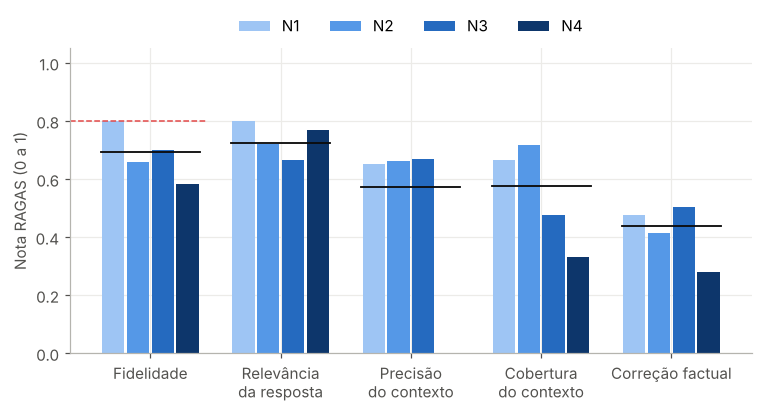

In [6]:
# Figura: métricas do assistente por nível
mets = list(METRICAS)
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(mets)); larg = .19
tons = ["#9ec5f4", "#5598e7", "#256abf", "#0d366b"]  # sequencial azul: N1 -> N4
for i, nv in enumerate(NIVEIS):
    g = res[(res.condicao == "RAG") & (res.nivel == nv)].set_index("metrica").reindex(mets)
    ax.bar(x + (i - 1.5) * larg, g.media, larg - .02, color=tons[i], label=nv)
geral = res[(res.condicao == "RAG") & (res.nivel == "Todos")].set_index("metrica").reindex(mets)
for xi, v in zip(x, geral.media):
    ax.plot([xi - 2 * larg, xi + 2 * larg], [v, v], color="#0b0b0b", lw=1.2)
ax.axhline(LIMIAR["faithfulness"], xmin=0, xmax=.2, color="#e34948", ls="--", lw=1)
ax.set_xticks(x, [METRICAS[m].replace(" do ", "\ndo ").replace(" da ", "\nda ") for m in mets])
ax.set_ylim(0, 1.05); ax.set_ylabel("Nota RAGAS (0 a 1)")
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(.5, 1.15))
salvar_fig(fig, "fig_ragas_niveis")

In [7]:
# QP2 automática: Wilcoxon pareado RAG × B1 (FactualCorrectness e ResponseRelevancy)
def wilcoxon_pareado(metrica):
    p = porq[porq.metrica == metrica].pivot_table(index=["id", "nivel"], columns="condicao", values="valor").dropna().reset_index()
    d = p["RAG"] - p["B1"]
    nz = d[d != 0]
    t = stats.wilcoxon(p["RAG"], p["B1"], zero_method="wilcox", alternative="two-sided")
    # correlação bisserial de postos (tamanho de efeito para Wilcoxon pareado)
    r = stats.rankdata(nz.abs())
    rbc = (r[nz > 0].sum() - r[nz < 0].sum()) / r.sum()
    return p, dict(metrica=METRICAS[metrica], n=len(p), mediana_RAG=p.RAG.median(), mediana_B1=p.B1.median(),
                   media_RAG=p.RAG.mean(), media_B1=p.B1.mean(),
                   RAG_maior=int((d > 0).sum()), empates=int((d == 0).sum()), B1_maior=int((d < 0).sum()),
                   W=t.statistic, p=t.pvalue, r_rb=rbc)

pares, testes = {}, []
for m in ["FactualCorrectness", "ResponseRelevancy"]:
    pares[m], t = wilcoxon_pareado(m); testes.append(t)
wil = pd.DataFrame(testes)
display(wil.round(3))

tab_wil = pd.DataFrame({
    "Métrica": wil.metrica, "Média assistente": wil.media_RAG.map(br), "Média B1": wil.media_B1.map(br),
    "Assistente > B1 / empate / B1 >": wil.apply(lambda r: f"{r.RAG_maior} / {r.empates} / {r.B1_maior}", axis=1),
    "W": wil.W.map(lambda v: br(v, 1)), "p": wil.p.map(lambda v: br(v, 3)), "r (bisserial)": wil.r_rb.map(br)})
salvar_tabela(tab_wil, "02_wilcoxon_rag_b1", "Comparação pareada entre o assistente e o B1 (teste de Wilcoxon, n = 15)",
              "tab:wilcoxon", fonte="Elaborado pelo autor. r: correlação bisserial de postos (tamanho de efeito).",
              colfmt=cols(("l", 2.6), ("c", 1.5), ("c", 1.3), ("c", 2.8), ("c", 1.0), ("c", 1.1), ("c", 1.6)))

,metrica,n,mediana_RAG,mediana_B1,media_RAG,media_B1,RAG_maior,empates,B1_maior,W,p,r_rb
0,Correção factual,15,0.52,0.400,0.439,0.374,9,1,5,29.0,0.140,0.448
1,Relevância da resposta,15,0.72,0.708,0.726,0.632,10,0,5,39.0,0.252,0.350


,Métrica,Média assistente,Média B1,Assistente > B1 / empate / B1 >,W,p,r (bisserial)
0,Correção factual,"0,44","0,37",9 / 1 / 5,"29,0","0,140","0,45"
1,Relevância da resposta,"0,73","0,63",10 / 0 / 5,"39,0","0,252","0,35"


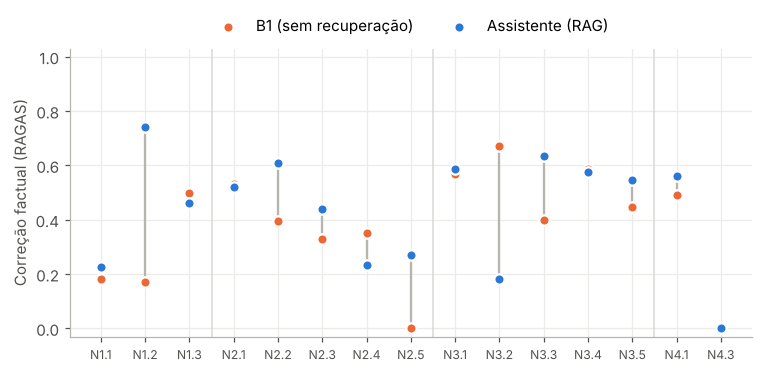

In [8]:
# Figura: correção factual pareada por pergunta (RAG × B1)
p = pares["FactualCorrectness"].sort_values(["nivel", "id"]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 3.4))
for i, r in p.iterrows():
    ax.plot([i, i], [r.B1, r.RAG], color="#b5b4ae", lw=1.5, zorder=1)
ax.scatter(p.index, p.B1, s=46, color=COR["B1"], label="B1 (sem recuperação)", zorder=2, edgecolor="white", linewidth=1.5)
ax.scatter(p.index, p.RAG, s=46, color=COR["RAG"], label="Assistente (RAG)", zorder=3, edgecolor="white", linewidth=1.5)
ax.set_xticks(p.index, p.id, rotation=0, fontsize=8)
for nv in NIVEIS[1:]:
    ax.axvline(p.index[p.nivel == nv].min() - .5, color="#d9d8d4", lw=1)
ax.set_ylim(-.03, 1.03); ax.set_ylabel("Correção factual (RAGAS)")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(.5, 1.16))
salvar_fig(fig, "fig_correcao_factual_pareada")

## 2. Frente D — Métricas operacionais

Latência (mediana e p95), *tokens* e custo por interação a partir do conjunto congelado. O *cold start* entra se existir `data/eval/cold_start.csv` com as colunas `tipo` (`fria` ou `quente`) e `latencia_ms`.

In [9]:
rag_m = pd.json_normalize(itens["rag_metricas"]).add_prefix("rag_")
b1_m = pd.json_normalize(itens["baseline_metricas"]).add_prefix("b1_")
op = pd.concat([itens[["id", "nivel", "pergunta"]], rag_m, b1_m], axis=1)

def p95(s): return np.percentile(s, 95)
lat = pd.DataFrame([
    ["Assistente", "Busca (embedding + pgvector)", op.rag_latencia_busca_ms],
    ["Assistente", "Geração (LLM)", op.rag_latencia_geracao_ms],
    ["Assistente", "Total", op.rag_latencia_total_ms],
    ["B1", "Geração (LLM)", op.b1_latencia_geracao_ms],
], columns=["Condição", "Etapa", "s"])
tab_lat = pd.DataFrame({"Condição": lat["Condição"], "Etapa": lat.Etapa,
                        "Mediana (s)": lat.s.map(lambda s: br(s.median() / 1000, 1)),
                        "P95 (s)": lat.s.map(lambda s: br(p95(s) / 1000, 1)),
                        "Mín.–máx. (s)": lat.s.map(lambda s: f"{br(s.min()/1000,1)}–{br(s.max()/1000,1)}")})
salvar_tabela(tab_lat, "03_latencia", "Latência por etapa nas 16 perguntas do conjunto congelado", "tab:latencia",
              fonte="Elaborado pelo autor. Medido na execução do script de geração (máquina local, API da OpenAI e Supabase remotos).")
display(tab_lat)
LAT_MEDIANA_S = op.rag_latencia_total_ms.median() / 1000

,Condição,Etapa,Mediana (s),P95 (s),Mín.–máx. (s)
0,Assistente,Busca (embedding + pgvector),"2,0","2,8","1,4–3,5"
1,Assistente,Geração (LLM),"3,9","5,2","2,4–6,1"
2,Assistente,Total,"5,9","7,5","3,8–7,7"
3,B1,Geração (LLM),"3,9","6,1","2,9–6,8"


In [10]:
# custo por interação (USD) — tokens × preço; embedding da pergunta estimado em ~4 caracteres por token
emb_tokens = op.pergunta.str.len().div(4).apply(math.ceil)
op["custo_rag"] = (op.rag_tokens_in * PRECO["gpt-4o-mini_in"] + op.rag_tokens_out * PRECO["gpt-4o-mini_out"]
                   + emb_tokens * PRECO["embedding_small"]) / 1e6
op["custo_b1"] = (op.b1_tokens_in * PRECO["gpt-4o-mini_in"] + op.b1_tokens_out * PRECO["gpt-4o-mini_out"]) / 1e6

def linha(cond, tin, tout, custo):
    mes = custo.mean() * INTERACOES_USUARIO_MES
    d = {"Condição": cond, "Tokens de entrada (média)": br(tin.mean(), 0), "Tokens de saída (média)": br(tout.mean(), 0),
         "Custo por interação (US$)": br(custo.mean(), 5),
         f"Custo por usuário/mês, {INTERACOES_USUARIO_MES} perguntas (US$)": br(mes, 3)}
    if USD_BRL: d["Por usuário/mês (R$)"] = br(mes * USD_BRL, 2)
    return d
tab_custo = pd.DataFrame([linha("Assistente", op.rag_tokens_in, op.rag_tokens_out, op.custo_rag),
                          linha("B1", op.b1_tokens_in, op.b1_tokens_out, op.custo_b1)])
salvar_tabela(tab_custo, "04_custo", "Tokens e custo estimado por interação", "tab:custo",
              fonte=f"Elaborado pelo autor com base na tabela de preços da OpenAI de {PRECO['data_tabela']} "
                    f"(gpt-4o-mini: US\\$ {br(PRECO['gpt-4o-mini_in'])} e US\\$ {br(PRECO['gpt-4o-mini_out'])} por milhão de tokens de entrada e saída).",
              colfmt=cols(("l", 2.0), ("c", 2.4), ("c", 2.4), ("c", 2.9), ("c", 3.4)))
display(tab_custo)
print(f"O contexto recuperado multiplica a entrada por {op.rag_tokens_in.mean()/op.b1_tokens_in.mean():.1f}x.")

,Condição,Tokens de entrada (média),Tokens de saída (média),Custo por interação (US$),"Custo por usuário/mês, 100 perguntas (US$)"
0,Assistente,2755,165,"0,00051","0,051"
1,B1,1342,175,"0,00031","0,031"


O contexto recuperado multiplica a entrada por 2.1x.


In [11]:
cs_path = EVAL / "cold_start.csv"
if cs_path.exists():
    cs = pd.read_csv(cs_path)
    tab_cs = cs.groupby("tipo")["latencia_ms"].agg(n="count", mediana="median", minimo="min", maximo="max").div(
        [1, 1000, 1000, 1000]).reset_index()
    salvar_tabela(tab_cs, "05_cold_start", "Tempo de resposta após inatividade (cold start) e em requisições seguidas",
                  "tab:cold-start", casas=1)
    display(tab_cs)
else:
    print("PENDENTE: cold_start.csv não encontrado. Meça 5 requisições após >= 15 min sem uso e 5 seguidas na aplicação "
          "publicada (DevTools > Network, tempo da chamada /chat) e grave com as colunas tipo,latencia_ms.")

PENDENTE: cold_start.csv não encontrado. Meça 5 requisições após >= 15 min sem uso e 5 seguidas na aplicação publicada (DevTools > Network, tempo da chamada /chat) e grave com as colunas tipo,latencia_ms.


## 3. Frente B — Avaliação cega pelos especialistas (QP2)

A planilha de codificação liga cada código (R01–R32) à pergunta e à condição. Escores: Correta = 1, Parcialmente = 0,5, Incorreta = 0.
Se existir `data/eval/especialistas_consenso.csv` (colunas `Código`, `Correção factual`), o consenso substitui a média dos dois avaliadores nos critérios.

In [12]:
cod = pd.read_excel(EVAL / "especialistas_codificacao.xlsx", sheet_name="Codificação")[["Código", "ID", "Nível", "Condição"]]
COLS = ["codigo", "nivel_txt", "pergunta", "resposta", "referencia", "correcao", "sem_suporte", "qual",
        "fontes", "vigencia", "n4", "comentario"]

def ler_avaliador(k):
    f = sorted(RESP.glob(f"*avaliacao_cega_avaliador_{k}*.xlsx"))
    assert f, f"planilha do avaliador {k} não encontrada em {RESP}"
    a = pd.read_excel(f[-1], sheet_name="Avaliação")
    assert a.columns[5].startswith("Correção factual") and len(a.columns) == 12, "layout da planilha mudou"
    a.columns = COLS
    a = a.merge(cod, left_on="codigo", right_on="Código", how="left")
    assert a["ID"].notna().all() and len(a) == 32
    a["avaliador"] = f"A{k}"
    return a

esp = pd.concat([ler_avaliador(1), ler_avaliador(2)], ignore_index=True)
esp["cond"] = esp["Condição"].map({"RAG": "Assistente", "B1": "B1"})
ESCORE = {"Correta": 1.0, "Parcialmente correta": 0.5, "Incorreta": 0.0}
esp["escore"] = esp.correcao.map(ESCORE)
assert esp.escore.notna().all(), esp.correcao.unique()
for c in ["correcao", "sem_suporte", "fontes", "vigencia", "n4"]:
    print(c, esp[c].value_counts().to_dict())

correcao {'Parcialmente correta': 25, 'Correta': 23, 'Incorreta': 16}
sem_suporte {'Não': 35, 'Sim': 29}
fontes {'Não cita fontes': 32, 'Sim': 20, 'Parcialmente': 12}
vigencia {'Não se aplica': 30, 'Sim': 22, 'Não': 11, 'Não sei': 1}
n4 {'Não se aplica': 52, 'Sim': 6, 'Não': 6}


In [13]:
# concordância entre avaliadores: kappa de Cohen (ponderado linear para a correção, que é ordinal)
def kappa(a, b, categorias, pesos=None):
    idx = {c: i for i, c in enumerate(categorias)}; k = len(categorias)
    O = np.zeros((k, k))
    for x, y in zip(a, b): O[idx[x], idx[y]] += 1
    O /= O.sum()
    E = np.outer(O.sum(1), O.sum(0))
    W = (np.abs(np.subtract.outer(np.arange(k), np.arange(k))) / (k - 1)) if pesos == "linear" else (1 - np.eye(k))
    return 1 - (W * O).sum() / (W * E).sum()

w1 = esp[esp.avaliador == "A1"].set_index("codigo"); w2 = esp[esp.avaliador == "A2"].set_index("codigo").loc[w1.index]
itens_k = [("Correção factual", "correcao", ["Incorreta", "Parcialmente correta", "Correta"], "linear"),
           ("Afirmação sem suporte", "sem_suporte", ["Não", "Sim"], None),
           ("Fontes sustentam a resposta", "fontes", ["Não cita fontes", "Não", "Parcialmente", "Sim"], None),
           ("Vigência da regra", "vigencia", ["Não se aplica", "Não sei", "Não", "Sim"], None),
           ("Armadilha N4 tratada", "n4", ["Não se aplica", "Não", "Parcialmente", "Sim"], None)]
kap = []
for nome, col, cats, pes in itens_k:
    cats = [c for c in cats] + sorted(set(w1[col]) | set(w2[col]) - set(cats))
    kap.append([nome, "ponderado (linear)" if pes else "simples", pct((w1[col] == w2[col]).mean()),
                br(kappa(w1[col], w2[col], cats, pes))])
tab_kappa = pd.DataFrame(kap, columns=["Critério", "Kappa", "Concordância observada", "κ"])
salvar_tabela(tab_kappa, "06_kappa_especialistas", "Concordância entre os dois especialistas nas 32 respostas", "tab:kappa",
              fonte="Elaborado pelo autor. Interpretação usual: 0,41–0,60 moderada; 0,61–0,80 substancial; > 0,80 quase perfeita.")
display(tab_kappa)

div = pd.DataFrame({"Código": w1.index, "ID": w1.ID, "Condição": w1["Condição"], "A1": w1.correcao, "A2": w2.correcao})
div = div[div.A1 != div.A2]
div.to_csv(TAB / "06b_divergencias_para_consenso.csv", index=False, encoding="utf-8-sig")
print(f"{len(div)} divergências na correção factual (lista em tabelas/06b_divergencias_para_consenso.csv):")
div

,Critério,Kappa,Concordância observada,κ
0,Correção factual,ponderado (linear),91%,"0,80"
1,Afirmação sem suporte,simples,91%,"0,81"
2,Fontes sustentam a resposta,simples,100%,"1,00"
3,Vigência da regra,simples,97%,"0,95"
4,Armadilha N4 tratada,simples,100%,"1,00"


3 divergências na correção factual (lista em tabelas/06b_divergencias_para_consenso.csv):


,Código,ID,Condição,A1,A2
codigo,,,,,
R09,R09,N1.3,RAG,Correta,Parcialmente correta
R16,R16,N3.4,B1,Parcialmente correta,Correta
R21,R21,N3.2,B1,Parcialmente correta,Correta


In [14]:
# consenso (se houver) ou média dos dois avaliadores
cons_path = EVAL / "especialistas_consenso.csv"
por_resp = esp.groupby(["codigo", "ID", "Nível", "Condição", "cond"], as_index=False)["escore"].mean()
if cons_path.exists():
    cons = pd.read_csv(cons_path)
    por_resp = por_resp.drop(columns="escore").merge(
        cons.assign(escore=cons["Correção factual"].map(ESCORE))[["Código", "escore"]], left_on="codigo", right_on="Código")
    FONTE_ESP = "consenso"
else:
    FONTE_ESP = "média dos dois avaliadores"
print("Escore por resposta usa:", FONTE_ESP)

# Tabela por condição × nível e por avaliador: % correta / parcial / incorreta, % sem suporte, % fontes que sustentam
def props(g):
    return pd.Series({"n": len(g), "Correta": (g.correcao == "Correta").mean(),
                      "Parcial": (g.correcao == "Parcialmente correta").mean(), "Incorreta": (g.correcao == "Incorreta").mean(),
                      "Escore": g.escore.mean(), "Sem suporte": (g.sem_suporte == "Sim").mean(),
                      "Fontes sustentam": (g.fontes == "Sim").mean(), "Sem fonte": (g.fontes == "Não cita fontes").mean(),
                      "Regra não vigente": (g.vigencia == "Não").mean()})
pc = esp.groupby(["cond", "Nível", "avaliador"]).apply(props).reset_index()
pc_tot = esp.groupby(["cond", "avaliador"]).apply(props).reset_index().assign(**{"Nível": "Geral"})
pc = pd.concat([pc, pc_tot]).sort_values(["cond", "Nível", "avaliador"])

ag = pc.groupby(["cond", "Nível"]).mean(numeric_only=True).reset_index()  # média dos 2 avaliadores
tab_esp = pd.DataFrame({
    "Condição": ag.cond, "Nível": ag["Nível"],
    "Correta": ag.Correta.map(pct), "Parcial": ag.Parcial.map(pct), "Incorreta": ag.Incorreta.map(pct),
    "Escore médio": ag.Escore.map(br), "Com afirmação sem suporte": ag["Sem suporte"].map(pct),
    "Fontes sustentam": ag["Fontes sustentam"].map(pct), "Regra não vigente": ag["Regra não vigente"].map(pct)})
salvar_tabela(tab_esp, "07_especialistas_por_nivel",
              "Julgamento dos especialistas por condição e nível (média das proporções dos dois avaliadores)",
              "tab:especialistas-nivel",
              fonte="Elaborado pelo autor. Escore: correta = 1, parcialmente correta = 0,5, incorreta = 0.",
              colfmt=cols(("l", 1.7), ("c", 0.9), ("c", 1.2), ("c", 1.2), ("c", 1.4), ("c", 1.2), ("c", 1.6), ("c", 1.4), ("c", 1.4)),
              tam="footnotesize")
tab_esp

Escore por resposta usa: média dos dois avaliadores


,Condição,Nível,Correta,Parcial,Incorreta,Escore médio,Com afirmação sem suporte,Fontes sustentam,Regra não vigente
0,Assistente,Geral,41%,47%,12%,"0,64",34%,62%,19%
1,Assistente,N1,50%,50%,0%,"0,75",33%,67%,0%
2,Assistente,N2,0%,80%,20%,"0,40",60%,40%,40%
3,Assistente,N3,60%,40%,0%,"0,80",10%,100%,0%
4,Assistente,N4,67%,0%,33%,"0,67",33%,33%,33%
5,B1,Geral,31%,31%,38%,"0,47",56%,0%,16%
6,B1,N1,67%,33%,0%,"0,83",33%,0%,0%
7,B1,N2,0%,40%,60%,"0,20",80%,0%,20%
8,B1,N3,40%,40%,20%,"0,60",30%,0%,0%
9,B1,N4,33%,0%,67%,"0,33",83%,0%,50%


,cond,avaliador,Correta,Parcial,Incorreta,Sem suporte,Fontes sustentam
0,Assistente,A1,0.438,0.438,0.125,0.375,0.625
1,Assistente,A2,0.375,0.500,0.125,0.312,0.625
2,B1,A1,0.250,0.375,0.375,0.500,0.000
3,B1,A2,0.375,0.250,0.375,0.625,0.000


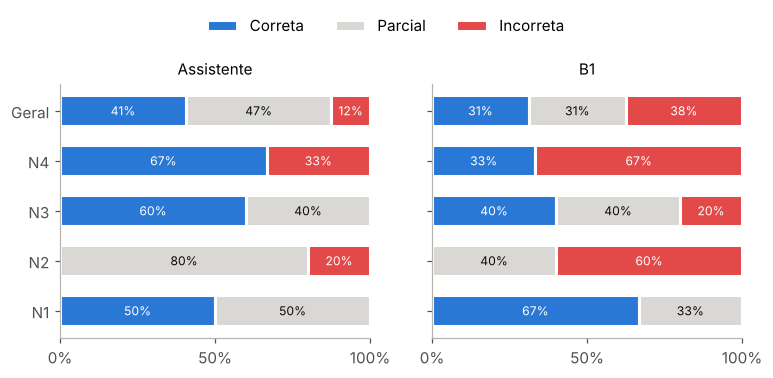

In [15]:
# por avaliador (para o texto e para o critério 2)
display(pc[pc["Nível"] == "Geral"][["cond", "avaliador", "Correta", "Parcial", "Incorreta", "Sem suporte", "Fontes sustentam"]].round(3))

# Figura: correção por condição e nível (barras empilhadas 100%, média dos avaliadores)
fig, axs = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
cores = {"Correta": DIV5[4], "Parcial": DIV5[2], "Incorreta": DIV5[0]}
for ax, c in zip(axs, ["Assistente", "B1"]):
    g = ag[ag.cond == c].set_index("Nível").reindex(NIVEIS + ["Geral"])
    esq = np.zeros(len(g))
    for cat in ["Correta", "Parcial", "Incorreta"]:
        ax.barh(g.index, g[cat], left=esq, color=cores[cat], height=.62, edgecolor="white", linewidth=2, label=cat)
        for y, (l, v) in enumerate(zip(esq, g[cat])):
            if v >= .12: ax.text(l + v / 2, y, f"{v*100:.0f}%", ha="center", va="center", fontsize=8,
                                 color="white" if cat != "Parcial" else "#0b0b0b")
        esq += g[cat].values
    ax.set_title(c, fontsize=10); ax.set_xlim(0, 1); ax.invert_yaxis(); ax.grid(False)
    ax.set_xticks([0, .5, 1], ["0%", "50%", "100%"])
axs[0].legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(1.05, 1.32))
salvar_fig(fig, "fig_especialistas_correcao")

In [16]:
# N4 uma a uma (as três armadilhas), nas duas condições
n4 = esp[esp["Nível"] == "N4"].pivot_table(index=["ID", "cond"], columns="avaliador",
                                             values=["correcao", "n4"], aggfunc="first")
n4.columns = [f"{a}_{b}" for a, b in n4.columns]
n4 = n4.reset_index()
tab_n4 = pd.DataFrame({"Pergunta": n4.ID, "Condição": n4.cond,
                       "Correção (A1 / A2)": n4.correcao_A1 + " / " + n4.correcao_A2,
                       "Tratou a armadilha (A1 / A2)": n4.n4_A1 + " / " + n4.n4_A2})
salvar_tabela(tab_n4, "08_armadilhas_n4", "Tratamento das perguntas-armadilha (N4) segundo os especialistas", "tab:n4")
tab_n4

,Pergunta,Condição,Correção (A1 / A2),Tratou a armadilha (A1 / A2)
0,N4.1,Assistente,Correta / Correta,Sim / Sim
1,N4.1,B1,Correta / Correta,Sim / Sim
2,N4.2,Assistente,Correta / Correta,Sim / Sim
3,N4.2,B1,Incorreta / Incorreta,Não / Não
4,N4.3,Assistente,Incorreta / Incorreta,Não / Não
5,N4.3,B1,Incorreta / Incorreta,Não / Não


In [17]:
# afirmações sem suporte apontadas (material para a discussão e para os casos de falha)
sup = esp[esp.sem_suporte == "Sim"][["ID", "cond", "avaliador", "qual"]].sort_values(["ID", "cond", "avaliador"])
sup.to_csv(TAB / "09_afirmacoes_sem_suporte.csv", index=False, encoding="utf-8-sig")
print(sup.groupby("cond").ID.nunique().rename("perguntas com ao menos 1 apontamento"))
sup

cond
Assistente     6
B1            10
Name: perguntas com ao menos 1 apontamento, dtype: int64


,ID,cond,avaliador,qual
29,N1.1,Assistente,A1,"""Preservam o principal investido"": não é verdade em todos os casos. Há risco..."
61,N1.1,Assistente,A2,"""Preservam o principal investido"" e ""sabe quanto irá receber"": renda fixa ta..."
4,N1.1,B1,A1,Define renda fixa como algo em que se sabe o rendimento final já na aplicaçã...
36,N1.1,B1,A2,"""O investidor sabe, no momento da aplicação, qual será o rendimento"": isso s..."
9,N2.1,Assistente,A1,"A frase final diz que o limite total ""pode ser maior"" conforme o número de b..."
41,N2.1,Assistente,A2,"""O limite total de garantia pode ser maior, dependendo do número de institui..."
12,N2.1,B1,A1,Afirma que não existe teto total para quem tem aplicações em vários bancos. ...
44,N2.1,B1,A2,"""Não há um teto total para quem tem aplicações em vários bancos"": existe o t..."
14,N2.2,B1,A1,"Diz que, após as 13h, o crédito sai sempre no próximo dia útil. Para vendas ..."
46,N2.2,B1,A2,"""Se for após esse horário, o crédito ocorre no próximo dia útil"": não vale s..."


## 4. Frente C — Investidores iniciantes (QP3)

Limpeza → triagem (TCLE, maioridade, situação, formação, certificação) → checagem de atenção → perfil, tarefas, BUS-11 e TAM.

In [18]:
ff = sorted(RESP.glob("*respostas forms*.xlsx")) + sorted(EVAL.glob("forms_*.xlsx")) + sorted(EVAL.glob("forms_*.csv"))
assert ff, "export do Forms não encontrado"
raw = pd.read_excel(ff[0]) if ff[0].suffix == ".xlsx" else pd.read_csv(ff[0])
print(ff[0].name, raw.shape, "| de", raw.iloc[:, 0].min(), "a", raw.iloc[:, 0].max())

NOMES = ["ts", "tcle", "maior", "situacao", "formacao", "certificacao", "idade", "escolaridade", "area", "produtos",
         "conhecimento", "usou_ia", "b3_juros", "b3_inflacao", "b3_risco", "dispositivo",
         "t1", "t1_dific", "t2_recebeu", "t2_compr", "t3", "t4_contexto", "t4_compr", "t5_pergunta", "t5_ajudou", "t5_fonte",
         *[f"bus{i}" for i in range(1, 12)],
         "pu1", "pu2", "peou1", "peou2", "atencao", "bi1", "bi2", "cf1",
         "aberta_ajudou", "aberta_faltou", "comparacao", "comparacao_pq", "comentario"]
assert len(NOMES) == raw.shape[1] == 50, "o Forms mudou de layout"
# conferência leve por palavra-chave, para não trocar colunas por engano
for i, chave in [(16, "criar a conta"), (20, "documento oficial"), (26, "função de conversa"), (36, "tempo de espera"),
                 (41, "marque 2"), (44, "fontes oficiais"), (47, "Google")]:
    assert chave in raw.columns[i], (i, raw.columns[i])
fr = raw.copy(); fr.columns = NOMES
fr["pid_raw"] = range(len(fr))

def likert(v):
    if pd.isna(v): return np.nan
    m = re.match(r"\s*(\d)", str(v)); return float(m.group(1)) if m else np.nan
BUS = [f"bus{i}" for i in range(1, 12)]; TAM = ["pu1", "pu2", "peou1", "peou2", "bi1", "bi2", "cf1"]
for c in BUS + TAM + ["atencao", "conhecimento", "t2_compr", "t4_compr", "t5_ajudou"]:
    fr[c] = fr[c].map(likert)

# triagem
SITUACOES_OK = ("Ainda não invisto", "Invisto há menos de 1 ano", "Invisto há entre 1 e 3 anos")
fr["motivo_exclusao"] = ""
fr.loc[~fr.tcle.astype(str).str.startswith("Li e concordo"), "motivo_exclusao"] += "sem TCLE; "
fr.loc[fr.maior != "Sim", "motivo_exclusao"] += "menor de idade; "
fr.loc[~fr.situacao.astype(str).str.startswith(SITUACOES_OK), "motivo_exclusao"] += "investe há 3 anos ou mais; "
fr.loc[fr.formacao != "Não", "motivo_exclusao"] += "formação em Economia/Adm./Contábeis; "
fr.loc[(fr.certificacao.notna()) & (fr.certificacao != "Não"), "motivo_exclusao"] += "certificação; "
fr.loc[fr[BUS + TAM].isna().all(axis=1) & (fr.motivo_exclusao == ""), "motivo_exclusao"] += "incompleto; "

# atenção: o item "marque 2" deveria filtrar; se veio vazio para todos, não discrimina -> usa straightlining
atencao_ok = fr.atencao.notna().any()
print("Item de atenção respondido por alguém?", atencao_ok)
if atencao_ok:
    fr.loc[(fr.motivo_exclusao == "") & (fr.atencao != 2), "motivo_exclusao"] += "falhou no item de atenção; "
fr["straightlining"] = fr[BUS].nunique(axis=1).eq(1) & fr[TAM].nunique(axis=1).eq(1)
print("Respostas com o mesmo valor em todos os itens do BUS-11 e do TAM:", int(fr.straightlining.sum()))

# substituto do item de atenção: mesmo valor em TODOS os itens das duas escalas E abertas sem conteúdo
ABERTAS = ["aberta_ajudou", "aberta_faltou", "comparacao_pq"]
fr["abertas_vazias"] = fr[ABERTAS].apply(lambda r: all(len(re.sub(r"\W", "", str(x))) == 0 or pd.isna(x) for x in r), axis=1)
fr["desatento"] = fr.straightlining & fr.abertas_vazias
display(fr.loc[fr.straightlining, ["pid_raw", "bus1", "pu1", "aberta_ajudou", "aberta_faltou", "comparacao_pq", "desatento"]])
EXCLUIR_DESATENTOS = True
if EXCLUIR_DESATENTOS:
    fr.loc[(fr.motivo_exclusao == "") & fr.desatento, "motivo_exclusao"] += "resposta desatenta (mesmo valor em tudo e abertas vazias); "
excl = fr[fr.motivo_exclusao != ""][["pid_raw", "ts", "motivo_exclusao"]]
v = fr[fr.motivo_exclusao == ""].copy().reset_index(drop=True)
v["pid"] = [f"P{i+1:02d}" for i in range(len(v))]
N = len(v)
print(f"\nRecebidas: {len(fr)} | excluídas: {len(excl)} | válidas: {N}")
excl

Avaliação Rev – respostas forms.xlsx (19, 50) | de 2026-11-16 11:34:48.377000 a 2026-11-17 11:07:29.305000
Item de atenção respondido por alguém? False
Respostas com o mesmo valor em todos os itens do BUS-11 e do TAM: 3


,pid_raw,bus1,pu1,aberta_ajudou,aberta_faltou,comparacao_pq,desatento
3,3,5.0,7.0,clareza na explicação do raciocínio por trás de cada resposta como mostrar o...,"Eu achei muito completo, não faltou nem confundiu nada.","achei as explicações mais diretas, organizadas ou úteis do que uma busca com...",False
11,11,5.0,7.0,As referências. Me deram mais confiança nas sugestões disponibilizadas pelo ...,"Acredito que esteja tudo em ordem. Para mim, não faltou nada.",Por conta da precisão em demonstrar as fontes utilizadas claramente.,False
14,14,3.0,3.0,.,.,.,True



Recebidas: 19 | excluídas: 2 | válidas: 17


,pid_raw,ts,motivo_exclusao
4,4,2026-11-16 12:24:42.613,formação em Economia/Adm./Contábeis;
14,14,2026-11-16 16:27:41.607,resposta desatenta (mesmo valor em tudo e abertas vazias);


In [19]:
# Perfil da amostra + Big Three (só caracterização)
v["b3_acertos"] = ((v.b3_juros == "Mais de R$ 102").astype(int) + (v.b3_inflacao == "Menos do que hoje").astype(int)
                   + (v.b3_risco == "Falso").astype(int))
def dist(col, rotulo):
    vc = v[col].fillna("Não respondeu").astype(str).str.strip().value_counts()
    return [[rotulo, k, f"{n} ({100*n/N:.0f}%)"] for k, n in vc.items()]
perfil = (dist("situacao", "Situação") + dist("idade", "Faixa etária") + dist("escolaridade", "Escolaridade")
          + dist("dispositivo", "Dispositivo") + dist("usou_ia", "Já usou IA para dúvidas financeiras")
          + [["Conhecimento autodeclarado (1–5)", "Mediana", br(v.conhecimento.median(), 1)]]
          + [["Big Three", f"{k} de 3 acertos", f"{n} ({100*n/N:.0f}%)"] for k, n in v.b3_acertos.value_counts().sort_index(ascending=False).items()]
          + [["Big Three", "Acertos por pergunta (juros / inflação / risco)",
              f"{(v.b3_juros=='Mais de R$ 102').sum()} / {(v.b3_inflacao=='Menos do que hoje').sum()} / {(v.b3_risco=='Falso').sum()}"]])
tab_perfil = pd.DataFrame(perfil, columns=["Característica", "Categoria", f"n (%) — N = {N}"])
tab_perfil["Característica"] = tab_perfil["Característica"].where(tab_perfil["Característica"].ne(tab_perfil["Característica"].shift()), "")
salvar_tabela(tab_perfil, "10_perfil_participantes", "Perfil dos participantes válidos", "tab:perfil",
              colfmt=cols(("l", 4.2), ("l", 6.6), ("c", 3.0)))
tab_perfil

,Característica,Categoria,n (%) — N = 17
0,Situação,"Ainda não invisto, mas tenho interesse em começar",11 (65%)
1,,Invisto há menos de 1 ano,3 (18%)
2,,Invisto há entre 1 e 3 anos,3 (18%)
3,Faixa etária,18 a 24 anos,15 (88%)
4,,25 a 34 anos,2 (12%)
5,Escolaridade,Ensino superior incompleto ou em andamento,13 (76%)
6,,Ensino superior completo,3 (18%)
7,,Ensino médio completo,1 (6%)
8,Dispositivo,Celular,11 (65%)
9,,Computador,6 (35%)


In [20]:
# Tarefas T1–T5
suc = {
    "T1": v.t1.astype(str).str.startswith("Sim"),
    "T2": v.t2_recebeu.eq("Sim"),
    "T3": v.t3.eq("Sim"),
    "T4": v.t4_contexto.eq("Sim"),
}
tar = [
    ["T1", "Criar conta e abrir o chat", f"{suc['T1'].sum()}/{N}", pct(suc["T1"].mean()), pct(LIMIAR["tarefas"]["T1"]), "--"],
    ["T2", "Pergunta do FGC (N3.1)", f"{suc['T2'].sum()}/{N}", pct(suc["T2"].mean()), pct(LIMIAR["tarefas"]["T2"]),
     f"compreensão: mediana {br(v.t2_compr.median(),0)}, média {br(v.t2_compr.mean(),1)}"],
    ["T3", "Conferir a fonte no documento", f"{suc['T3'].sum()}/{N}", pct(suc["T3"].mean()), pct(LIMIAR["tarefas"]["T3"]),
     " / ".join(f"{k}: {n}" for k, n in v.t3.value_counts().items())],
    ["T4", "Pergunta de seguimento (LCA)", f"{suc['T4'].sum()}/{N}", pct(suc["T4"].mean()), pct(LIMIAR["tarefas"]["T4"]),
     f"parcialmente: {(v.t4_contexto=='Parcialmente').sum()}; compreensão: mediana {br(v.t4_compr.median(),0)}, média {br(v.t4_compr.mean(),1)}"],
    ["T5", "Dúvida real do participante", "--", "--", "--",
     f"ajudou: mediana {br(v.t5_ajudou.median(),0)}, média {br(v.t5_ajudou.mean(),1)}; citou fonte: {(v.t5_fonte=='Sim').sum()}/{N}"],
]
tab_tar = pd.DataFrame(tar, columns=["Tarefa", "Descrição", "Sucesso", "Taxa", "Meta", "Observações"])
salvar_tabela(tab_tar, "11_tarefas", "Resultado das tarefas T1 a T5", "tab:tarefas",
              colfmt="|c|p{3.6cm}|c|c|c|p{5.2cm}|")
tab_tar

,Tarefa,Descrição,Sucesso,Taxa,Meta,Observações
0,T1,Criar conta e abrir o chat,17/17,100%,80%,--
1,T2,Pergunta do FGC (N3.1),17/17,100%,80%,"compreensão: mediana 5, média 4,5"
2,T3,Conferir a fonte no documento,16/17,94%,70%,Sim: 16 / Não: 1
3,T4,Pergunta de seguimento (LCA),15/17,88%,80%,"parcialmente: 2; compreensão: mediana 5, média 4,5"
4,T5,Dúvida real do participante,--,--,--,"ajudou: mediana 5, média 4,5; citou fonte: 7/17"


In [21]:
# BUS-11 (Borsci et al., 2023): 5 fatores
FATORES_BUS = {"F1 Acessibilidade às funções": ["bus1", "bus2"],
               "F2 Qualidade das funções": ["bus3", "bus4", "bus5"],
               "F3 Qualidade da conversa e da informação": ["bus6", "bus7", "bus8", "bus9"],
               "F4 Privacidade e segurança": ["bus10"],
               "F5 Tempo de resposta": ["bus11"]}
def cronbach(df):
    df = df.dropna(); k = df.shape[1]
    if k < 2: return np.nan
    return k / (k - 1) * (1 - df.var(ddof=1).sum() / df.sum(axis=1).var(ddof=1))

linhas = []
for f, its in FATORES_BUS.items():
    s = v[its].mean(axis=1)
    linhas.append([f, len(its), br(s.mean()), br(s.std(ddof=1)), br(s.median(), 1), br(cronbach(v[its])) if len(its) > 1 else "--"])
bus_geral = v[BUS].mean(axis=1)
linhas.append(["BUS-11 geral", 11, br(bus_geral.mean()), br(bus_geral.std(ddof=1)), br(bus_geral.median(), 1), br(cronbach(v[BUS]))])
tab_bus = pd.DataFrame(linhas, columns=["Fator", "Itens", "Média", "DP", "Mediana", "α de Cronbach"])
salvar_tabela(tab_bus, "12_bus11", f"Usabilidade percebida pela BUS-11 (escala de 1 a 5, N = {N})", "tab:bus11",
              fonte="Elaborado pelo autor com base em \\citeonline{borsci2023confirmatory}. Com N pequeno, o $\\alpha$ é apenas indicativo.",
              colfmt="|l|c|c|c|c|c|")
BUS_GERAL = bus_geral.mean(); BUS_F3 = v[FATORES_BUS["F3 Qualidade da conversa e da informação"]].mean(axis=1).mean()
tab_bus

,Fator,Itens,Média,DP,Mediana,α de Cronbach
0,F1 Acessibilidade às funções,2,"4,53","0,86","5,0","0,96"
1,F2 Qualidade das funções,3,"4,41","0,85","4,7","0,93"
2,F3 Qualidade da conversa e da informação,4,"4,15","0,82","4,5","0,86"
3,F4 Privacidade e segurança,1,"3,88","1,11","4,0",--
4,F5 Tempo de resposta,1,"4,24","1,03","5,0",--
5,BUS-11 geral,11,"4,27","0,82","4,5","0,96"


In [22]:
# TAM: mediana, média ± DP, % de 5–7 por construto; Spearman entre os 2 itens
CONSTR = {"Utilidade percebida": ["pu1", "pu2"], "Facilidade de uso": ["peou1", "peou2"],
          "Intenção de uso": ["bi1", "bi2"], "Confiança nas fontes (complementar)": ["cf1"]}
linhas, TAM_MED = [], {}
for c, its in CONSTR.items():
    s = v[its].mean(axis=1); TAM_MED[c] = s.median()
    rho = stats.spearmanr(v[its[0]], v[its[1]]).statistic if len(its) == 2 else np.nan
    linhas.append([c, br(s.median(), 1), f"{br(s.mean())} ± {br(s.std(ddof=1))}", pct((v[its] >= 5).mean().mean()),
                   br(rho) if len(its) == 2 else "--"])
tab_tam = pd.DataFrame(linhas, columns=["Construto", "Mediana", "Média ± DP", "Notas de 5 a 7", "ρ entre os itens"])
salvar_tabela(tab_tam, "13_tam", f"Aceitação pelos itens adaptados do TAM (escala de 1 a 7, N = {N})", "tab:tam",
              fonte="Elaborado pelo autor com base em \\citeonline{davis1989perceived}.",
              colfmt=cols(("l", 4.2), ("c", 1.6), ("c", 2.4), ("c", 2.0), ("c", 2.0)))
tab_tam

,Construto,Mediana,Média ± DP,Notas de 5 a 7,ρ entre os itens
0,Utilidade percebida,"6,5","6,00 ± 1,56",79%,"0,44"
1,Facilidade de uso,"7,0","6,09 ± 1,56",79%,"0,93"
2,Intenção de uso,"6,5","5,74 ± 1,70",82%,"0,83"
3,Confiança nas fontes (complementar),"7,0","6,12 ± 1,58",82%,--


In [23]:
# Tabela única para o TCC: BUS-11 (1 a 5) e TAM (1 a 7)
linhas = []
for f, its in FATORES_BUS.items():
    sc = v[its].mean(axis=1)
    linhas.append(["BUS-11 (1 a 5)", f[3:], len(its), f"{br(sc.mean())} ± {br(sc.std(ddof=1))}", br(sc.median(), 1),
                   f"α = {br(cronbach(v[its]))}" if len(its) > 1 else "--"])
linhas.append(["BUS-11 (1 a 5)", "Geral", 11, f"{br(bus_geral.mean())} ± {br(bus_geral.std(ddof=1))}", br(bus_geral.median(), 1),
               f"α = {br(cronbach(v[BUS]))}"])
for c, its in CONSTR.items():
    sc = v[its].mean(axis=1)
    rho = f"ρ = {br(stats.spearmanr(v[its[0]], v[its[1]]).statistic)}" if len(its) == 2 else "--"
    linhas.append(["TAM (1 a 7)", c, len(its), f"{br(sc.mean())} ± {br(sc.std(ddof=1))}", br(sc.median(), 1), rho])
tab_ua = pd.DataFrame(linhas, columns=["Instrumento", "Dimensão", "Itens", "Média ± DP", "Mediana", "Consistência"])
tab_ua["Instrumento"] = tab_ua["Instrumento"].where(tab_ua["Instrumento"].ne(tab_ua["Instrumento"].shift()), "")
salvar_tabela(tab_ua, "12b_usabilidade_aceitacao", f"Usabilidade (BUS-11) e aceitação (TAM) do assistente (N = {N})",
              "tab:usabilidade-aceitacao",
              fonte="Elaborado pelo autor com base em \\citeonline{borsci2023confirmatory} e \\citeonline{davis1989perceived}. "
                    "Consistência: $\\alpha$ de Cronbach (fatores com 3 ou mais itens) ou correlação de Spearman (2 itens).",
              colfmt=cols(("l", 2.0), ("l", 4.5), ("c", 0.9), ("c", 2.1), ("c", 1.4), ("c", 2.2)))
tab_ua

,Instrumento,Dimensão,Itens,Média ± DP,Mediana,Consistência
0,BUS-11 (1 a 5),Acessibilidade às funções,2,"4,53 ± 0,86","5,0","α = 0,96"
1,,Qualidade das funções,3,"4,41 ± 0,85","4,7","α = 0,93"
2,,Qualidade da conversa e da informação,4,"4,15 ± 0,82","4,5","α = 0,86"
3,,Privacidade e segurança,1,"3,88 ± 1,11","4,0",--
4,,Tempo de resposta,1,"4,24 ± 1,03","5,0",--
5,,Geral,11,"4,27 ± 0,82","4,5","α = 0,96"
6,TAM (1 a 7),Utilidade percebida,2,"6,00 ± 1,56","6,5","ρ = 0,44"
7,,Facilidade de uso,2,"6,09 ± 1,56","7,0","ρ = 0,93"
8,,Intenção de uso,2,"5,74 ± 1,70","6,5","ρ = 0,83"
9,,Confiança nas fontes (complementar),1,"6,12 ± 1,58","7,0",--


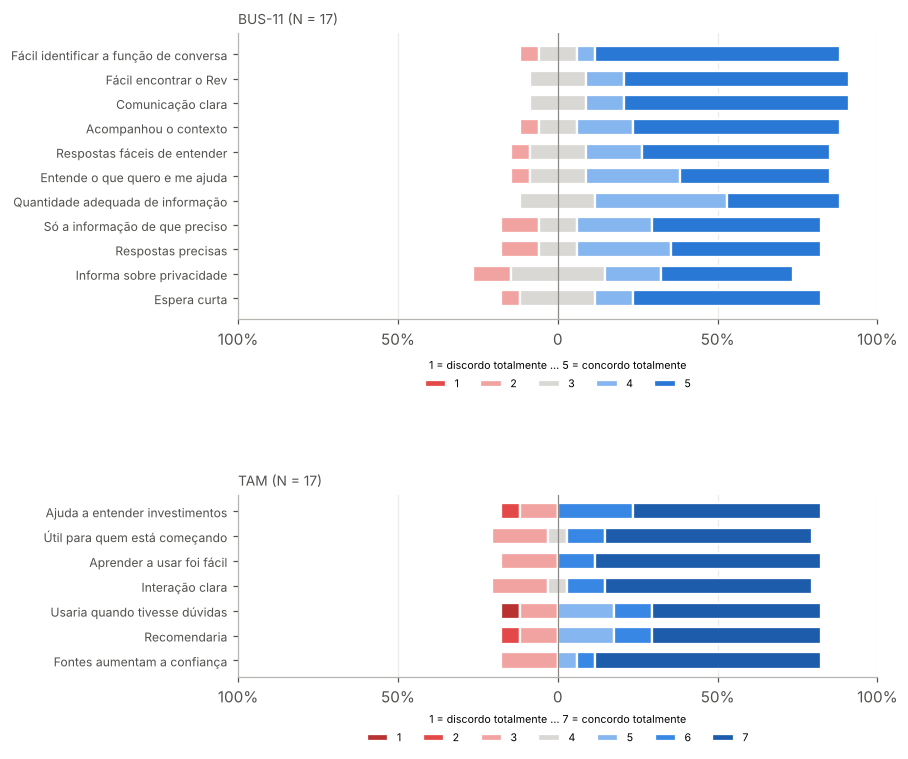

In [24]:
# Figura: distribuição das respostas (barras divergentes) — BUS-11 e TAM
ROT_BUS = ["Fácil identificar a função de conversa", "Fácil encontrar o Rev", "Comunicação clara", "Acompanhou o contexto",
           "Respostas fáceis de entender", "Entende o que quero e me ajuda", "Quantidade adequada de informação",
           "Só a informação de que preciso", "Respostas precisas", "Informa sobre privacidade", "Espera curta"]
ROT_TAM = ["Ajuda a entender investimentos", "Útil para quem está começando", "Aprender a usar foi fácil",
           "Interação clara", "Usaria quando tivesse dúvidas", "Recomendaria", "Fontes aumentam a confiança"]

def divergente(ax, df, rotulos, k, cores, titulo):
    cont = np.array([[(df[c] == s).sum() for s in range(1, k + 1)] for c in df.columns]) / len(df)
    meio = k // 2
    esq = -(cont[:, :meio].sum(1) + cont[:, meio] / 2)
    for s in range(k):
        ax.barh(range(len(rotulos)), cont[:, s], left=esq, color=cores[s], height=.66, edgecolor="white", linewidth=1.5,
                label=str(s + 1))
        esq = esq + cont[:, s]
    ax.set_yticks(range(len(rotulos)), rotulos, fontsize=8); ax.invert_yaxis()
    ax.axvline(0, color="#8a8984", lw=.8); ax.set_xlim(-1, 1); ax.grid(axis="y", visible=False)
    ax.set_xticks([-1, -.5, 0, .5, 1], ["100%", "50%", "0", "50%", "100%"])
    ax.set_title(titulo, fontsize=9, color=COR["texto"], loc="left")
    ax.legend(ncol=k, frameon=False, fontsize=7, loc="lower center", bbox_to_anchor=(.5, -.42 if k == 7 else -.28), title_fontsize=7,
              title="1 = discordo totalmente … " + str(k) + " = concordo totalmente")

fig, axs = plt.subplots(2, 1, figsize=(7.5, 7.6), gridspec_kw={"height_ratios": [11, 7], "hspace": .75})
divergente(axs[0], v[BUS], ROT_BUS, 5, DIV5, f"BUS-11 (N = {N})")
divergente(axs[1], v[TAM], ROT_TAM, 7, DIV7, f"TAM (N = {N})")
salvar_fig(fig, "fig_bus_tam_divergente")

In [25]:
# Comparação declarada com Google/ChatGPT (aberta 3) — medida direta de preferência
comp = v.comparacao.fillna("Não respondeu").value_counts()
tab_comp = pd.DataFrame({"Em comparação com o Google ou o ChatGPT, o Rev foi": comp.index,
                         "n": comp.values, "%": [pct(x / N) for x in comp.values]})
salvar_tabela(tab_comp, "14_comparacao_google_chatgpt", "Comparação declarada entre o Rev e a pesquisa no Google ou o ChatGPT",
              "tab:comparacao", colfmt="|l|c|c|")
tab_comp

,"Em comparação com o Google ou o ChatGPT, o Rev foi",n,%
0,Melhor,9,53%
1,Nunca usei essas opções para tirar dúvidas sobre investimentos,4,24%
2,Igual,3,18%
3,Pior,1,6%


## 5. Análise qualitativa (análise temática)

**Codificação proposta pelo Claude e revisada (18/11).** Os códigos estão nos dicionários abaixo, indexados pela linha do export do Forms (`pid_raw`), para que a revisão seja só editar o dicionário e rodar de novo. Códigos → temas → frequência + citações representativas.

In [26]:
COD_AJUDOU = {0: ["Aprendizado sobre investimentos"], 1: ["Clareza", "Objetividade", "Fontes e confiabilidade"], 2: ["Clareza"],
              3: ["Clareza", "Exemplos e aplicação prática"], 5: ["Objetividade", "Fontes e confiabilidade"], 6: ["Objetividade"],
              7: ["Exemplos e aplicação prática"], 8: ["Clareza"], 9: ["Rapidez", "Fontes e confiabilidade"],
              10: ["Exemplos e aplicação prática"], 11: ["Fontes e confiabilidade"], 12: ["Rapidez", "Fontes e confiabilidade"],
              13: ["Clareza"], 14: [], 15: ["Fontes e confiabilidade"], 16: ["Rapidez", "Fontes e confiabilidade", "Clareza"],
              17: ["Clareza"], 18: ["Clareza", "Objetividade"]}
COD_FALTOU = {0: ["Nada a apontar"], 1: ["Interface e outras funções do app"], 2: ["Nada a apontar"], 3: ["Nada a apontar"],
              5: ["Tamanho e repetição das respostas"], 6: ["Nada a apontar"], 7: ["Cálculos e simulações"], 8: ["Nada a apontar"],
              9: ["Nada a apontar"], 10: ["Conceito não esclarecido"], 11: ["Nada a apontar"],
              12: ["Tamanho e repetição das respostas"], 13: ["Interface e outras funções do app"], 14: [], 15: ["Nada a apontar"],
              16: ["Nada a apontar"], 17: ["Escopo e dados atuais"], 18: ["Tempo de resposta"]}
COD_PQ = {0: ["Objetividade"], 1: ["Foco em finanças e didática", "Outras IAs mais completas"], 2: ["Sem base de comparação"],
          3: ["Objetividade"], 5: ["Foco em finanças e didática"], 6: ["Sem base de comparação"], 7: ["Foco em finanças e didática"],
          8: ["Foco em finanças e didática"], 9: ["Sem base de comparação"], 10: ["Equivalência"],
          11: ["Fontes e confiabilidade"], 12: ["Outras IAs mais completas"], 13: ["Equivalência"], 14: [],
          15: ["Sem base de comparação"], 16: ["Fontes e confiabilidade"], 17: ["Fontes e confiabilidade", "Clareza", "Rapidez"],
          18: ["Objetividade"]}
COD_T5 = {0: "Como começar a investir", 1: "Conceitos e produtos", 2: "Como começar a investir", 3: "Recomendação e conjuntura",
          5: "Como começar a investir", 6: "Regras (FGC)", 7: "Simulação e cálculo", 8: "Como começar a investir",
          9: "Recomendação e conjuntura", 10: "Conceitos e produtos", 11: "Recomendação e conjuntura",
          12: "Recomendação e conjuntura", 13: "Recomendação e conjuntura", 14: "Criptoativos", 15: "Como começar a investir",
          16: "Tributação", 17: "Simulação e cálculo", 18: "Como começar a investir"}

def temas(col, codigos, titulo, nome):
    linhas = []
    for pr, cods in codigos.items():
        if pr not in set(v.pid_raw): continue
        for c in cods: linhas.append((c, pr))
    t = pd.DataFrame(linhas, columns=["tema", "pid_raw"])
    def curto(txt, lim=110):
        txt = " ".join(str(txt).split())
        return txt if len(txt) <= lim else txt[:lim].rsplit(" ", 1)[0].rstrip(",.;:") + " [...]"
    out, usados = [], set()
    ordem = t.groupby("tema").pid_raw.nunique().sort_values().index  # temas menores escolhem primeiro
    for tema in ordem:
        g = t[t.tema == tema]
        cand = [x for x in g.pid_raw if x not in usados] or list(g.pid_raw)  # evita repetir a mesma citação em temas diferentes
        esc = cand[:1] if len(g) < 3 else cand[:2]
        usados.update(esc)
        exemplos = [curto(v.set_index("pid_raw").loc[x, col]) for x in esc]
        out.append([tema, g.pid_raw.nunique(), pct(g.pid_raw.nunique() / N), " | ".join(f"“{e}”" for e in exemplos)])
    df = pd.DataFrame(out, columns=["Tema", "Participantes", "%", "Exemplos"]).sort_values("Participantes", ascending=False)
    faltando = set(v.pid_raw) - set(codigos)
    if faltando: print("ATENÇÃO: respostas sem código:", sorted(faltando))
    salvar_tabela(df, nome, titulo, f"tab:{nome}", colfmt=cols(("l", 3.2), ("c", 2.2), ("c", 1.0), ("l", 7.4)))
    return df

display(temas("aberta_ajudou", COD_AJUDOU, "Temas: o que mais ajudou nas respostas do Rev", "15_temas_ajudou"))
display(temas("aberta_faltou", COD_FALTOU, "Temas: o que confundiu, irritou ou faltou", "16_temas_faltou"))
display(temas("comparacao_pq", COD_PQ, "Temas: por que o Rev foi melhor, igual ou pior que Google ou ChatGPT", "17_temas_comparacao"))

# Tabela única para o TCC: temas das três perguntas abertas, sem as citações (que vão no texto)
def contagem(codigos):
    t = pd.Series([c for pr, cs in codigos.items() if pr in set(v.pid_raw) for c in cs]).value_counts()
    return t
blocos = [("O que mais ajudou", COD_AJUDOU), ("O que confundiu ou faltou", COD_FALTOU),
          ("Por que melhor, igual ou pior que Google/ChatGPT", COD_PQ)]
linhas = []
for nome, cod_ in blocos:
    for i, (tema, n) in enumerate(contagem(cod_).items()):
        linhas.append([nome if i == 0 else "", tema, f"{n} ({pct(n / N)})"])
tab_temas = pd.DataFrame(linhas, columns=["Pergunta aberta", "Tema", f"Participantes (N = {N})"])
salvar_tabela(tab_temas, "15b_temas_abertas", "Temas identificados nas respostas às perguntas abertas", "tab:temas",
              fonte="Elaborado pelo autor. Uma resposta pode ter mais de um tema.",
              colfmt=cols(("l", 4.4), ("l", 6.2), ("c", 3.2)))
display(tab_temas)

,Tema,Participantes,%,Exemplos
5,Clareza,8,47%,“Responder as minhas dúvidas de forma clara e simples de entender” | “Fácil ...
4,Fontes e confiabilidade,7,41%,“As referências. Me deram mais confiança nas sugestões disponibilizadas pelo...
3,Objetividade,4,24%,"“As respostas são simples e objetivas, mas ao mesmo tempo explicativas. Com ..."
1,Exemplos e aplicação prática,3,18%,“clareza na explicação do raciocínio por trás de cada resposta como mostrar ...
2,Rapidez,3,18%,“A velocidade e precisão” | “Respostas rápidas sobre minhas dúvidas com maio...
0,Aprendizado sobre investimentos,1,6%,“Entender melhor sobre investimentos”


,Tema,Participantes,%,Exemplos
6,Nada a apontar,9,53%,“Nada” | “Nas minhas perguntas não teve nenhuma problema”
4,Interface e outras funções do app,2,12%,“Eu não encontrei a opção de iniciar um novo chat com o Rev. Gostaria de ter...
5,Tamanho e repetição das respostas,2,12%,"“Em contra partida a outra resposta, as vezes ele dá uma resposta muito brev..."
2,Escopo e dados atuais,1,6%,"“Na minha pergunta, imaginei que ele fosse pesquisar a informação na interne..."
1,Cálculos e simulações,1,6%,“Faltou precisão quando eu pedi que ele fizesse uma simulação do quanto que ...
0,Conceito não esclarecido,1,6%,“Eu n entendi muito sobre a diferença de CDBs LCIs LCAs”
3,Tempo de resposta,1,6%,"“Apenas a demora nas respostas, nada concreto - as vezes pode ser a internet.”"


,Tema,Participantes,%,Exemplos
6,Foco em finanças e didática,4,24%,“Para quem tá começando com investimentos o Rev aparenta ser uma opção super...
7,Sem base de comparação,4,24%,“Nunca usei” | “normalmente tiro minhas duvidas diretamente com professores ...
4,Objetividade,3,18%,"“Achei que ele fala somento o necessario, nao se extende muito” | “achei as ..."
5,Fontes e confiabilidade,3,18%,“Por conta da precisão em demonstrar as fontes utilizadas claramente.” | “ci...
2,Outras IAs mais completas,2,12%,“Acredito que com o contexto que o Rev tinha sobre as minhas dúvidas e situa...
3,Equivalência,2,12%,"“Não uso outros aplicativos pra isso, mais com oque eu tenho costume de pesq..."
0,Clareza,1,6%,"“Clareza, velocidade e fontes claras”"
1,Rapidez,1,6%,"“Clareza, velocidade e fontes claras”"


,Pergunta aberta,Tema,Participantes (N = 17)
0,O que mais ajudou,Clareza,8 (47%)
1,,Fontes e confiabilidade,7 (41%)
2,,Objetividade,4 (24%)
3,,Exemplos e aplicação prática,3 (18%)
4,,Rapidez,3 (18%)
5,,Aprendizado sobre investimentos,1 (6%)
6,O que confundiu ou faltou,Nada a apontar,9 (53%)
7,,Interface e outras funções do app,2 (12%)
8,,Tamanho e repetição das respostas,2 (12%)
9,,Cálculos e simulações,1 (6%)


In [27]:
# T5: dúvidas reais × cobertura (proxy: a resposta citou fonte da base?)
v["t5_tema"] = v.pid_raw.map(COD_T5)
t5 = v.groupby("t5_tema").agg(n=("pid", "size"), citou_fonte=("t5_fonte", lambda s: (s == "Sim").sum()),
                             ajudou_mediana=("t5_ajudou", "median")).sort_values("n", ascending=False).reset_index()
tab_t5 = pd.DataFrame({"Tema da dúvida (T5)": t5.t5_tema, "n": t5.n, "Resposta citou fonte": t5.citou_fonte,
                       "Ajudou (mediana, 1–5)": t5.ajudou_mediana.map(lambda x: br(x, 1))})
salvar_tabela(tab_t5, "18_t5_temas", "Dúvidas reais feitas na T5, por tema", "tab:t5", colfmt="|l|c|c|c|")
display(tab_t5)
v[["pid", "t5_tema", "t5_pergunta", "t5_fonte", "t5_ajudou"]]

,Tema da dúvida (T5),n,Resposta citou fonte,"Ajudou (mediana, 1–5)"
0,Como começar a investir,6,1,"5,0"
1,Recomendação e conjuntura,5,3,"5,0"
2,Conceitos e produtos,2,1,"4,0"
3,Simulação e cálculo,2,1,"3,5"
4,Regras (FGC),1,0,"5,0"
5,Tributação,1,1,"5,0"


,pid,t5_tema,t5_pergunta,t5_fonte,t5_ajudou
0,P01,Como começar a investir,Com quantos anos eu posso começar a investir?,Sim,5.0
1,P02,Conceitos e produtos,O que é CDI e como investir nele? Poderia citar a taxa Selic?,Não,5.0
2,P03,Como começar a investir,Posso começar investindo apenas 100 reais por mês?,Não,5.0
3,P04,Recomendação e conjuntura,Com a política atual o melhor investimento é estrangeiro?,Sim,5.0
4,P05,Como começar a investir,"Eu consigo investir em alguma coisa, seja onde for, recebendo salário de até...",Não,4.0
5,P06,Regras (FGC),o limite do FGV pode ser ultrapassado?,Não,5.0
6,P07,Simulação e cálculo,Eu pedi que ele fizesse uma simulação do quanto eu tinha que guardar por mês...,Sim,4.0
7,P08,Como começar a investir,Como começar a investir hoje sem ter conhecimento,Não,5.0
8,P09,Recomendação e conjuntura,Se vale mais a pena investir em fundos imobiliários ou fazer meu próprio imó...,Não,4.0
9,P10,Conceitos e produtos,"Oque é CDBs, LCIs e LCAspp",Sim,3.0


## 6. Triangulação por pergunta e casos de falha

Uma linha por pergunta. "Baixo" em cada frente (parâmetros em `FALHA`): **A** = correção factual do assistente < 0,40 ou cobertura do contexto < 0,50; **B** = escore dos especialistas < 0,50 (ao menos um "incorreta"); **D** = latência total > 8 s. Duas ou mais frentes baixas = caso de falha.

In [28]:
pv = porq.pivot_table(index="id", columns=["condicao", "metrica"], values="valor")
tri = itens[["id", "nivel"]].set_index("id")
tri["FC assistente"] = pv.get(("RAG", "FactualCorrectness")); tri["FC B1"] = pv.get(("B1", "FactualCorrectness"))
tri["Fidelidade"] = pv.get(("RAG", "Faithfulness")); tri["Cobertura"] = pv.get(("RAG", "LLMContextRecall"))
e = por_resp.pivot_table(index="ID", columns="Condição", values="escore")
tri["Esp. assistente"] = e["RAG"]; tri["Esp. B1"] = e["B1"]
tri["Latência (s)"] = (op.set_index("id").rag_latencia_total_ms / 1000)

# dominância documental nos trechos recuperados
def doc_dom(fontes):
    docs = pd.Series([f["documento"] for f in fontes]); vc = docs.value_counts()
    return vc.index[0], vc.iloc[0] / len(docs)
dd = itens.set_index("id").fontes.apply(doc_dom)
tri["Documento dominante"] = dd.map(lambda t: t[0]); tri["Dominância"] = dd.map(lambda t: t[1])

baixoA = (tri["FC assistente"] < FALHA["fc_rag"]) | (tri["Cobertura"] < FALHA["recall"])
baixoB = tri["Esp. assistente"] < FALHA["esp_score"]
baixoD = tri["Latência (s)"] > FALHA["latencia_s"]
tri["Frentes baixas"] = (baixoA.fillna(False).map({True: "A", False: ""}) + baixoB.map({True: "B", False: ""})
                         + baixoD.map({True: "D", False: ""}))
tri["Caso de falha"] = tri["Frentes baixas"].str.len() >= 2
tri = tri.reset_index()
display(tri.round(2))

tab_tri = pd.DataFrame({
    "Pergunta": tri.id, "FC assist.": tri["FC assistente"].map(br), "FC B1": tri["FC B1"].map(br),
    "Fidel.": tri["Fidelidade"].map(br), "Cobert.": tri["Cobertura"].map(br),
    "Esp. assist.": tri["Esp. assistente"].map(br), "Esp. B1": tri["Esp. B1"].map(br),
    "Latência (s)": tri["Latência (s)"].map(lambda x: br(x, 1)),
    "Falha": tri.apply(lambda r: f"Sim ({r['Frentes baixas']})" if r["Caso de falha"] else (r["Frentes baixas"] or "--"), axis=1)})
salvar_tabela(tab_tri, "19_triangulacao", "Triangulação das frentes por pergunta", "tab:triangulacao",
              fonte="Elaborado pelo autor. FC: correção factual (RAGAS); Esp.: escore dos especialistas (correta = 1, parcial = 0,5, "
                    "incorreta = 0); Falha: frentes com desempenho baixo (A = RAGAS, B = especialistas, D = latência). "
                    "A N4.2 não tem métricas do RAGAS.",
              colfmt=cols(("l", 1.4), ("c", 1.3), ("c", 1.1), ("c", 1.1), ("c", 1.2), ("c", 1.3), ("c", 1.1), ("c", 1.4), ("c", 1.6)),
              tam="footnotesize")

,id,nivel,FC assistente,FC B1,Fidelidade,Cobertura,Esp. assistente,Esp. B1,Latência (s),Documento dominante,Dominância,Frentes baixas,Caso de falha
0,N1.1,N1,0.22,0.18,0.80,0.67,0.50,0.50,7.72,TOP Mercado de Valores Mobiliários Brasileiro (5ª ed.),0.4,A,False
1,N1.2,N1,0.74,0.17,1.00,1.00,1.00,1.00,7.42,Cadernos CVM nº 1 – O que é a CVM?,0.6,,False
2,N1.3,N1,0.46,0.50,0.60,0.33,0.75,1.00,6.34,TOP Planejamento Financeiro Pessoal (2ª ed.),0.6,A,False
3,N2.1,N2,0.52,0.53,0.60,0.67,0.50,0.00,5.50,TOP Planejamento Financeiro Pessoal (2ª ed.),0.8,,False
4,N2.2,N2,0.61,0.40,0.69,0.67,0.50,0.50,5.30,Regulamento do Tesouro Direto (versão de 11/10/2024),1.0,,False
5,N2.3,N2,0.44,0.33,0.67,0.25,0.50,0.00,3.80,TOP Direito do Mercado de Valores Mobiliários,0.8,A,False
6,N2.4,N2,0.24,0.35,0.60,1.00,0.50,0.50,5.53,TOP Direito do Mercado de Valores Mobiliários,0.4,A,False
7,N2.5,N2,0.27,0.00,0.75,1.00,0.00,0.00,4.14,TOP Mercado de Valores Mobiliários Brasileiro (5ª ed.),0.4,AB,True
8,N3.1,N3,0.58,0.57,0.56,0.33,0.50,0.00,7.38,Caderno de Educação Financeira – Gestão de Finanças Pessoais,0.4,A,False
9,N3.2,N3,0.18,0.67,0.80,0.75,0.50,0.75,6.25,TOP Direito do Mercado de Valores Mobiliários,0.8,A,False


,Pergunta,FC assist.,FC B1,Fidel.,Cobert.,Esp. assist.,Esp. B1,Latência (s),Falha
0,N1.1,"0,22","0,18","0,80","0,67","0,50","0,50","7,7",A
1,N1.2,"0,74","0,17","1,00","1,00","1,00","1,00","7,4",--
2,N1.3,"0,46","0,50","0,60","0,33","0,75","1,00","6,3",A
3,N2.1,"0,52","0,53","0,60","0,67","0,50","0,00","5,5",--
4,N2.2,"0,61","0,40","0,69","0,67","0,50","0,50","5,3",--
5,N2.3,"0,44","0,33","0,67","0,25","0,50","0,00","3,8",A
6,N2.4,"0,23","0,35","0,60","1,00","0,50","0,50","5,5",A
7,N2.5,"0,27","0,00","0,75","1,00","0,00","0,00","4,1",Sim (AB)
8,N3.1,"0,58","0,57","0,56","0,33","0,50","0,00","7,4",A
9,N3.2,"0,18","0,67","0,80","0,75","0,50","0,75","6,2",A


In [29]:
# N3.1 = T2: o mesmo cenário visto por especialistas e por usuários
n31 = tri[tri.id == "N3.1"].iloc[0]
print(f"N3.1 — FC assistente {n31['FC assistente']:.2f} | especialistas (assistente) {n31['Esp. assistente']:.2f} | "
      f"T2 compreensão mediana {v.t2_compr.median():.0f} | T3 achou a fonte {suc['T3'].mean():.0%}")
print("\nComentários dos especialistas sobre a resposta do assistente na N3.1:")
for _, r in esp[(esp.ID == "N3.1") & (esp["Condição"] == "RAG")].iterrows():
    print(f" {r.avaliador}: {r.correcao} | {r.qual if pd.notna(r.qual) else ''} | {r.comentario}")

# Casos de falha: o que veio na recuperação
for _, r in tri[tri["Caso de falha"]].iterrows():
    it = itens.set_index("id").loc[r.id]
    print(f"\n=== {r.id} ({r['Frentes baixas']}) — {it.pergunta}")
    for f in it.fontes:
        print(f"   {f['distancia']:.3f}  {f['documento'][:60]}  {f['pagina']}")
print("\nParticipação de cada documento nos 80 trechos recuperados:")
todas = pd.Series([f["documento"] for fs in itens.fontes for f in fs]).value_counts(normalize=True).round(3)
todas

N3.1 — FC assistente 0.58 | especialistas (assistente) 0.50 | T2 compreensão mediana 5 | T3 achou a fonte 94%

Comentários dos especialistas sobre a resposta do assistente na N3.1:
 A1: Parcialmente correta | "Garantindo a proteção total": ignora que CDB e LCI do mesmo conglomerado somam no limite e que a cobertura vale para o saldo com rendimentos. | Não usou o Tesouro na alocação, embora a pergunta pedisse, e não citou o teto de R$ 1 milhão.
 A2: Parcialmente correta |  | A divisão em R$ 200 mil por banco funciona, mas não usou o Tesouro como pedido, não avisou que CDB e LCI do mesmo banco somam no limite e não citou o teto de R$ 1 milhão.

=== N2.5 (AB) — Qual percentual mínimo de ações em circulação (free float) uma empresa do Novo Mercado precisa manter?
   0.228  TOP Mercado de Valores Mobiliários Brasileiro (5ª ed.)  p. 279
   0.244  TOP Direito do Mercado de Valores Mobiliários  p. 723-724
   0.267  TOP Mercado de Valores Mobiliários Brasileiro (5ª ed.)  p. 277
   0.271  Regula

TOP Direito do Mercado de Valores Mobiliários                                                  0.275
TOP Planejamento Financeiro Pessoal (2ª ed.)                                                   0.238
TOP Mercado de Valores Mobiliários Brasileiro (5ª ed.)                                         0.138
Regulamento do Tesouro Direto (versão de 11/10/2024)                                           0.100
Cadernos CVM nº 1 – O que é a CVM?                                                             0.062
Resolução CMN nº 4.222/2013 – Estatuto e Regulamento do FGC (texto consolidado)                0.050
Caderno de Educação Financeira – Gestão de Finanças Pessoais                                   0.038
Cadernos CVM nº 6 – Fundos de Investimento Imobiliário                                         0.038
Cadernos CVM nº 3 – Fundos de Investimento (3ª ed.)                                            0.025
Resolução CVM nº 44/2021 – Divulgação de Fato Relevante e negociação de valores mobiliários

## 7. Critérios de sucesso (Quadro 13 do TCC)

Cada critério sai como **Atingido**, **Não atingido** ou **Parcial / Divergente**, com o valor observado. Critério não atingido não é descartado: vira discussão e caso de falha.

In [30]:
def st(ok): return ok if isinstance(ok, str) else ("Atingido" if bool(ok) else "Não atingido")
crit = []
# 1
f_med = res.query("condicao=='RAG' and metrica=='Faithfulness' and nivel=='Todos'").media.iloc[0]
crit.append([1, "Fidelidade média do assistente ≥ 0,8", f"{br(f_med)}", st(f_med >= LIMIAR["faithfulness"])])
# 2 (por avaliador; só "Atingido" se os dois concordarem)
corr = pc[(pc.cond == "Assistente") & (pc["Nível"] == "Geral")].set_index("avaliador").Correta
ok2 = [x >= LIMIAR["corretas_especialistas"] for x in corr]
crit.append([2, "≥ 80% das respostas do assistente corretas (especialistas)",
             " / ".join(f"{a}: {pct(x)}" for a, x in corr.items()), st(all(ok2)) if len(set(ok2)) == 1 else "Divergente"])
# 3 RAG > B1 em N2–N4 (FC e especialistas)
fcn = res[(res.metrica == "FactualCorrectness")].pivot_table(index="nivel", columns="condicao", values="media")
esn = por_resp.groupby(["Nível", "Condição"]).escore.mean().unstack()
det, oks = [], []
for nv in ["N2", "N3", "N4"]:
    a = fcn.loc[nv, "RAG"] > fcn.loc[nv, "B1"]; b = esn.loc[nv, "RAG"] > esn.loc[nv, "B1"]
    oks.append(a and b); det.append(f"{nv}: FC {'>' if a else '≤'}, esp. {'>' if b else '≤'}")
crit.append([3, "Assistente > B1 em correção nos níveis N2 a N4 (FC e especialistas)", "; ".join(det),
             st(True) if all(oks) else ("Parcial" if any(oks) else st(False))])
# 4 menos afirmações sem suporte e mais fontes que sustentam
g = ag[ag["Nível"] == "Geral"].set_index("cond")
a4 = g.loc["Assistente", "Sem suporte"] < g.loc["B1", "Sem suporte"]; b4 = g.loc["Assistente", "Fontes sustentam"] > g.loc["B1", "Fontes sustentam"]
crit.append([4, "Menos afirmações sem suporte e mais fontes que sustentam do que o B1",
             f"sem suporte {pct(g.loc['Assistente','Sem suporte'])} × {pct(g.loc['B1','Sem suporte'])}; "
             f"fontes {pct(g.loc['Assistente','Fontes sustentam'])} × {pct(g.loc['B1','Fontes sustentam'])}",
             st(True) if a4 and b4 else ("Parcial" if a4 or b4 else st(False))])
# 5 armadilhas N4 (por avaliador)
n4r = esp[(esp["Nível"] == "N4") & (esp["Condição"] == "RAG")].groupby("avaliador").n4.apply(lambda s: (s == "Sim").sum())
ok5 = [x >= LIMIAR["n4_minimo"] for x in n4r]
crit.append([5, "Tratamento correto de ≥ 2 das 3 perguntas N4", " / ".join(f"{a}: {x} de 3" for a, x in n4r.items()),
             st(all(ok5)) if len(set(ok5)) == 1 else "Divergente"])
# 6 tarefas
ok6 = {t: suc[t].mean() >= LIMIAR["tarefas"][t] for t in ["T1", "T2", "T3", "T4"]}
crit.append([6, "Sucesso ≥ 80% em T1, T2 e T4 e ≥ 70% em T3",
             "; ".join(f"{t}: {pct(suc[t].mean())}" for t in ok6), st(all(ok6.values()))])
# 7 BUS-11
crit.append([7, "Média ≥ 4 no BUS-11 geral e no fator de qualidade da conversa e da informação",
             f"geral {br(BUS_GERAL)}; F3 {br(BUS_F3)}", st(BUS_GERAL >= LIMIAR["bus"] and BUS_F3 >= LIMIAR["bus"])])
# 8 TAM
t8 = {k: TAM_MED[k] for k in ["Utilidade percebida", "Facilidade de uso", "Intenção de uso"]}
crit.append([8, "Mediana ≥ 5 em utilidade, facilidade e intenção de uso (TAM)",
             "; ".join(f"{k.split()[0].lower()} {br(x,1)}" for k, x in t8.items()), st(all(x >= LIMIAR["tam"] for x in t8.values()))])
# 9 latência
crit.append([9, "Latência total mediana ≤ 8 s", f"{br(LAT_MEDIANA_S,1)} s", st(LAT_MEDIANA_S <= LIMIAR["latencia_s"])])
# 10 compreensão
crit.append([10, "Mediana ≥ 4 na compreensão das respostas da T2 e da T4",
             f"T2 {br(v.t2_compr.median(),0)}; T4 {br(v.t4_compr.median(),0)}",
             st(v.t2_compr.median() >= LIMIAR["compreensao"] and v.t4_compr.median() >= LIMIAR["compreensao"])])

tab_crit = pd.DataFrame(crit, columns=["#", "Critério", "Resultado observado", "Situação"])
salvar_tabela(tab_crit, "20_criterios_sucesso", "Situação dos critérios de sucesso definidos antes da coleta",
              "qua:criterios-resultado", quadro=True, colfmt="|c|p{5.6cm}|p{5.2cm}|p{2.2cm}|")
tab_crit

,#,Critério,Resultado observado,Situação
0,1,"Fidelidade média do assistente ≥ 0,8","0,69",Não atingido
1,2,≥ 80% das respostas do assistente corretas (especialistas),A1: 44% / A2: 38%,Não atingido
2,3,Assistente > B1 em correção nos níveis N2 a N4 (FC e especialistas),"N2: FC >, esp. >; N3: FC ≤, esp. >; N4: FC >, esp. >",Parcial
3,4,Menos afirmações sem suporte e mais fontes que sustentam do que o B1,sem suporte 34% × 56%; fontes 62% × 0%,Atingido
4,5,Tratamento correto de ≥ 2 das 3 perguntas N4,A1: 2 de 3 / A2: 2 de 3,Atingido
5,6,"Sucesso ≥ 80% em T1, T2 e T4 e ≥ 70% em T3",T1: 100%; T2: 100%; T3: 94%; T4: 88%,Atingido
6,7,Média ≥ 4 no BUS-11 geral e no fator de qualidade da conversa e da informação,"geral 4,27; F3 4,15",Atingido
7,8,"Mediana ≥ 5 em utilidade, facilidade e intenção de uso (TAM)","utilidade 6,5; facilidade 7,0; intenção 6,5",Atingido
8,9,Latência total mediana ≤ 8 s,"5,9 s",Atingido
9,10,Mediana ≥ 4 na compreensão das respostas da T2 e da T4,T2 5; T4 5,Atingido


In [31]:
# Sensibilidade: os resultados da frente C mudam se as respostas desatentas forem mantidas?
todos = fr[fr.motivo_exclusao.str.replace("resposta desatenta (mesmo valor em tudo e abertas vazias); ", "", regex=False) == ""]
def resumo_c(d):
    return pd.Series({"N": len(d), "BUS geral": d[BUS].mean(axis=1).mean(),
                      "BUS F3": d[["bus6", "bus7", "bus8", "bus9"]].mean(axis=1).mean(),
                      "TAM utilidade (mediana)": d[["pu1", "pu2"]].mean(axis=1).median(),
                      "TAM facilidade (mediana)": d[["peou1", "peou2"]].mean(axis=1).median(),
                      "TAM intenção (mediana)": d[["bi1", "bi2"]].mean(axis=1).median(),
                      "T3 sucesso": d.t3.eq("Sim").mean()})
pd.DataFrame({"Análise principal": resumo_c(v), "Mantendo desatentos": resumo_c(todos)}).round(2)

,Análise principal,Mantendo desatentos
N,17.00,18.00
BUS geral,4.27,4.20
BUS F3,4.15,4.08
TAM utilidade (mediana),6.50,6.50
TAM facilidade (mediana),7.00,7.00
TAM intenção (mediana),6.50,6.25
T3 sucesso,0.94,0.94


In [32]:
print("Arquivos gerados:")
for p in sorted(OUT.rglob("*.*")):
    print("  ", p.relative_to(EVAL))

Arquivos gerados:
   analise/figuras/fig_bus_tam_divergente.pdf
   analise/figuras/fig_bus_tam_divergente.png
   analise/figuras/fig_correcao_factual_pareada.pdf
   analise/figuras/fig_correcao_factual_pareada.png
   analise/figuras/fig_especialistas_correcao.pdf
   analise/figuras/fig_especialistas_correcao.png
   analise/figuras/fig_ragas_niveis.pdf
   analise/figuras/fig_ragas_niveis.png
   analise/tabelas/00_parametros_congelamento.csv
   analise/tabelas/00_parametros_congelamento.tex
   analise/tabelas/01_ragas_por_nivel.csv
   analise/tabelas/01_ragas_por_nivel.tex
   analise/tabelas/02_wilcoxon_rag_b1.csv
   analise/tabelas/02_wilcoxon_rag_b1.tex
   analise/tabelas/03_latencia.csv
   analise/tabelas/03_latencia.tex
   analise/tabelas/04_custo.csv
   analise/tabelas/04_custo.tex
   analise/tabelas/06_kappa_especialistas.csv
   analise/tabelas/06_kappa_especialistas.tex
   analise/tabelas/06b_divergencias_para_consenso.csv
   analise/tabelas/07_especialistas_por_nivel.csv
   anali